In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['font.size'] = 11

print('✅ Bibliothèques importées avec succès.')

✅ Bibliothèques importées avec succès.


In [5]:
# ======================================================
# 2) Création d'une base de données IPC mensuelle (Maroc)
#    basée sur la dynamique réelle publiée par le HCP
# ======================================================
# Période : janvier 2010 à décembre 2025 (192 mois)
dates = pd.date_range(start='2010-01-01', end='2025-12-01', freq='MS')
n = len(dates)

np.random.seed(42)

# On simule une trajectoire réaliste du taux d'inflation YoY au Maroc
# - période relativement stable avant 2021
# - choc inflationniste en 2022 (alimentation et énergie)
# - désinflation progressive ensuite
t = np.arange(n)

inflation_yoy = (
    1.20
    + 0.45 * np.sin(2 * np.pi * t / 12 + 1.2)          # saisonnalité faible
    + 0.18 * np.sin(2 * np.pi * t / 48)                 # cycle de moyen terme
    - 0.0008 * t                                        # légère tendance désinflationniste longue
)

# Choc de 2021-2023
inflation_yoy += 1.8 * np.exp(-0.5 * ((t - 140) / 8) ** 2)
inflation_yoy += 1.1 * np.exp(-0.5 * ((t - 146) / 10) ** 2)

# Bruit réaliste
noise = np.random.normal(0, 0.12, n)
inflation_yoy = inflation_yoy + noise

# Construction cohérente de l'IPC à partir de l'inflation YoY
ipc = np.zeros(n)
ipc[0] = 88.20  # base compatible avec la série réelle approximative

for i in range(1, n):
    inflation_mom_approx = inflation_yoy[i] / 12
    ipc[i] = ipc[i-1] * (1 + inflation_mom_approx / 100)

df = pd.DataFrame({
    'date': dates,
    'ipc': ipc.round(2),
    'inflation_yoy': inflation_yoy.round(2)
})

df.head(10)

,date,ipc,inflation_yoy
0,2010-01-01,88.20,1.68
1,2010-02-01,88.32,1.65
2,2010-03-01,88.44,1.67
3,2010-04-01,88.56,1.61
4,2010-05-01,88.65,1.19
5,2010-06-01,88.72,1.00
6,2010-07-01,88.81,1.09
7,2010-08-01,88.88,0.98
8,2010-09-01,88.95,0.94
9,2010-10-01,89.04,1.26


In [7]:
# Dimensions et informations générales
print('Dimensions du jeu de données :', df.shape)
print('\nInformations sur les variables :')
df.info()

Dimensions du jeu de données : (192, 3)

Informations sur les variables :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           192 non-null    datetime64[ns]
 1   ipc            192 non-null    float64       
 2   inflation_yoy  192 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 4.6 KB


In [8]:
# Vérification des valeurs manquantes et des doublons
print('Valeurs manquantes par variable :')
display(df.isnull().sum().to_frame('Nombre de NaN'))

print('\nNombre de doublons sur la date :', df['date'].duplicated().sum())
print('Type de la cible inflation_yoy :', df['inflation_yoy'].dtype)

Valeurs manquantes par variable :


,Nombre de NaN
date,0
ipc,0
inflation_yoy,0



Nombre de doublons sur la date : 0
Type de la cible inflation_yoy : float64


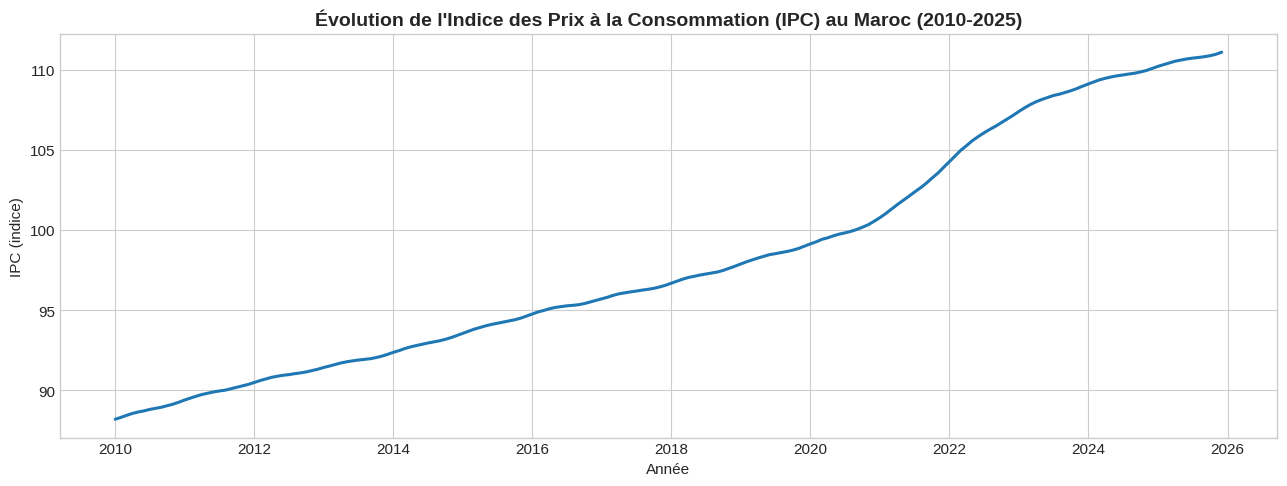

In [12]:
plt.figure(figsize=(13, 5))
plt.plot(df['date'], df['ipc'], color='#1f77b4', linewidth=2.2)
plt.title("Évolution de l'Indice des Prix à la Consommation (IPC) au Maroc (2010-2025)", fontweight='bold')
plt.xlabel('Année')
plt.ylabel('IPC (indice)')
plt.tight_layout()
plt.show()

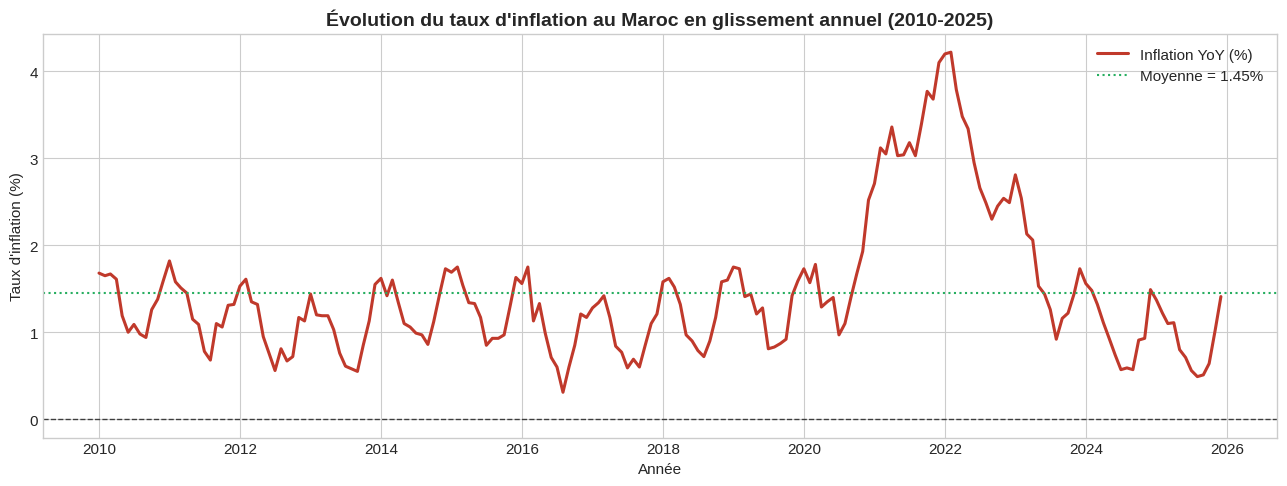

In [15]:
plt.figure(figsize=(13, 5))
plt.plot(df['date'], df['inflation_yoy'], color='#c0392b', linewidth=2.2, label='Inflation YoY (%)')
plt.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.7)
plt.axhline(df['inflation_yoy'].mean(), color='#27ae60', linewidth=1.5, linestyle=':', label=f"Moyenne = {df['inflation_yoy'].mean():.2f}%")
plt.title("Évolution du taux d'inflation au Maroc en glissement annuel (2010-2025)", fontweight='bold')
plt.xlabel('Année')
plt.ylabel("Taux d'inflation (%)")
plt.legend()
plt.tight_layout()
plt.show()

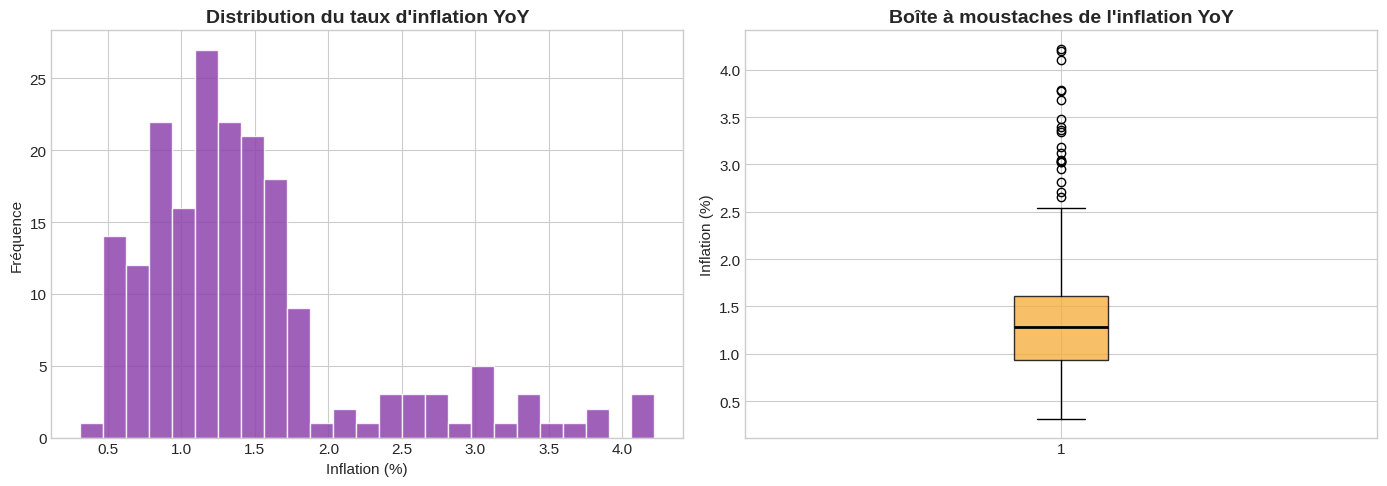

Statistiques descriptives de inflation_yoy :


,Valeur
count,192.000000
mean,1.451510
std,0.786981
min,0.310000
25%,0.930000
50%,1.285000
75%,1.610000
max,4.220000


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme
axes[0].hist(df['inflation_yoy'], bins=25, color='#8e44ad', edgecolor='white', alpha=0.85)
axes[0].set_title("Distribution du taux d'inflation YoY", fontweight='bold')
axes[0].set_xlabel("Inflation (%)")
axes[0].set_ylabel("Fréquence")

# Boxplot
axes[1].boxplot(df['inflation_yoy'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#f5b041', alpha=0.8),
                medianprops=dict(color='black', linewidth=2))
axes[1].set_title("Boîte à moustaches de l'inflation YoY", fontweight='bold')
axes[1].set_ylabel("Inflation (%)")

plt.tight_layout()
plt.show()

print('Statistiques descriptives de inflation_yoy :')
display(df['inflation_yoy'].describe().to_frame('Valeur'))

In [21]:
# Copie de travail pour le modèle
data = df.copy()

# Création des retards (lags 1 à 12) de l'inflation YoY
for lag in range(1, 13):
    data[f'lag_{lag}'] = data['inflation_yoy'].shift(lag)

# Création de moyennes mobiles historiques sur l'inflation passée (pour éviter les fuites, on shift de 1)
data['rolling_mean_3'] = data['inflation_yoy'].shift(1).rolling(window=3).mean()
data['rolling_mean_6'] = data['inflation_yoy'].shift(1).rolling(window=6).mean()
data['rolling_mean_12'] = data['inflation_yoy'].shift(1).rolling(window=12).mean()

# Variable saisonnière (le mois de l'année)
data['month'] = data['date'].dt.month

# Suppression des lignes contenant des valeurs manquantes créées par les décalages (lags)
data_model = data.dropna().reset_index(drop=True)

print('Dimensions d\'origine :', df.shape)
print('Dimensions après Feature Engineering :', data_model.shape)
display(data_model.head())

Dimensions d'origine : (192, 3)
Dimensions après Feature Engineering : (180, 19)


,date,ipc,inflation_yoy,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,month
0,2011-01-01,89.40,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.67,1.65,1.68,1.413333,1.208333,1.337500,1
1,2011-02-01,89.52,1.58,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.67,1.65,1.600000,1.330000,1.349167,2
2,2011-03-01,89.63,1.51,1.58,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.67,1.666667,1.430000,1.343333,3
3,2011-04-01,89.74,1.45,1.51,1.58,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.636667,1.525000,1.330000,4
4,2011-05-01,89.82,1.15,1.45,1.51,1.58,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.513333,1.556667,1.316667,5


In [23]:
# 1) Séparation des variables explicatives (X) et de la cible (y)
feature_cols = [f'lag_{i}' for i in range(1, 13)] + ['rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'month']
target_col = 'inflation_yoy'

X = data_model[feature_cols]
y = data_model[target_col]

# 2) Découpage chronologique (80% Train / 20% Test)
split_index = int(len(data_model) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

dates_train = data_model['date'].iloc[:split_index]
dates_test = data_model['date'].iloc[split_index:]

# 3) Définition du Pipeline Scikit-learn (Standardisation + RandomForest)
model_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=6,
        min_samples_leaf=3,
        random_state=42
    ))
])

print('Période d\'entraînement :', dates_train.min().strftime('%Y-%m'), '→', dates_train.max().strftime('%Y-%m'))
print('Période de test        :', dates_test.min().strftime('%Y-%m'), '→', dates_test.max().strftime('%Y-%m'))
print('\nNombre de variables explicatives :', X.shape[1])
print('Taille Train :', X_train.shape)
print('Taille Test  :', X_test.shape)
display(X_train.head(3))

Période d'entraînement : 2011-01 → 2022-12
Période de test        : 2023-01 → 2025-12

Nombre de variables explicatives : 16
Taille Train : (144, 16)
Taille Test  : (36, 16)


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,month
0,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.67,1.65,1.68,1.413333,1.208333,1.337500,1
1,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.67,1.65,1.600000,1.330000,1.349167,2
2,1.58,1.82,1.60,1.38,1.26,0.94,0.98,1.09,1.00,1.19,1.61,1.67,1.666667,1.430000,1.343333,3


In [27]:
# Entraînement du modèle sur les données d'entraînement uniquement
model_pipeline.fit(X_train, y_train)

print('✅ Modèle Random Forest entraîné avec succès sur la période historique.')

✅ Modèle Random Forest entraîné avec succès sur la période historique.


In [29]:
# 1) Prédictions sur l'ensemble de test
y_pred_rf = model_pipeline.predict(X_test)

# 2) Modèle de référence naïf (persistance) : l'inflation prévue à t est égale à l'inflation réelle à t-1 (lag_1)
y_pred_naive = X_test['lag_1'].values

# 3) Fonction d'évaluation des métriques de régression
def evaluate_predictions(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return pd.DataFrame({
        'Modèle': [name],
        'MAE': [mae],
        'RMSE': [rmse],
        'R² (Score)': [r2]
    })

# 4) Comparaison finale
results = pd.concat([
    evaluate_predictions(y_test, y_pred_naive, 'Modèle Naïf (Persistance)'),
    evaluate_predictions(y_test, y_pred_rf, 'Random Forest Regressor')
], ignore_index=True)

display(results.round(4))

,Modèle,MAE,RMSE,R² (Score)
0,Modèle Naïf (Persistance),0.1967,0.2420,0.8035
1,Random Forest Regressor,0.3295,0.4041,0.4522


In [32]:
# Prévision de l'inflation au Maroc à partir de son évolution passée

**Projet — Séries temporelles & Apprentissage automatique**

---

## Problématique

> **Comment peut-on prévoir l'inflation au Maroc à partir de son évolution passée ?**

Ce notebook répond à cette problématique en suivant les étapes clés : formulation du problème, exploration des données de l'IPC (HCP), préparation temporelle avec variables retardées (lags), puis modélisation par un algorithme de Machine Learning adapté.

SyntaxError: invalid character '—' (U+2014) (1735146718.py, line 3)